In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2


In [ ]:
users = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name = 'Пользователи')
payments = pd.read_excel('dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx', sheet_name = 'Платежи')


print("Размер таблицы:", users.shape)
display(users.head())

Размер таблицы: (1504, 5)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [ ]:
users.info()
print("\nПропуски по столбцам:")
print(users.isna().sum())
print("\nКоличество дубликатов строк:", users.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB

Пропуски по столбцам:
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

Количество дубликатов строк: 0


In [ ]:
print("Размер таблицы:", payments.shape)
display(payments.head())

Размер таблицы: (2661, 7)


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [ ]:
payments.info()
print("\nПропуски по столбцам:")
print(payments.isna().sum())
print("\nКоличество дубликатов строк:", payments.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB

Пропуски по столбцам:
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

Количество дубликатов строк: 0


In [ ]:
users_id = users['user_id']
payments['user_id'].isin(users_id).value_counts()

,count
user_id,
True,2660
False,1


In [ ]:
merged = payments.merge(
    users,
    on = 'user_id',
    how = 'left'
)

In [ ]:
(merged['group_x'] != merged['group_y']).value_counts()

,count
False,2659
True,2


In [ ]:
mask = merged['group_x'] != merged['group_y']
merged.loc[mask]

,payment_id,user_id,group_x,step1_opened,step2_entered,step3_confirmed,step4_success,group_y,age,city,device_type
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A,26.0,Москва,android
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT,NaN,NaN,NaN,NaN


In [ ]:
payments[payments['user_id'] == 1010]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
14,5015,1010.0,A,2024-04-27 13:26:00,NaT,NaT,NaT
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


In [ ]:
payments[(payments['step3_confirmed'].isna()) & (payments['step4_success'].notna())].shape

(0, 7)

In [ ]:
payments[payments['step1_opened'] > payments['step2_entered']].shape

(0, 7)

In [ ]:
payments[payments['step2_entered'] > payments['step3_confirmed']].shape

(0, 7)

In [ ]:
payments[payments['step3_confirmed'] > payments['step4_success']].shape

(0, 7)

In [ ]:
payments[(payments['step2_entered'].isna()) & (payments['step3_confirmed'].notna())].shape

(0, 7)

In [ ]:
print(payments['step1_opened'].min())
print(payments['step1_opened'].max())

2024-04-01 00:19:00
2024-04-30 23:17:00


In [ ]:
print(payments['step2_entered'].min())
print(payments['step2_entered'].max())

2024-04-01 00:23:00
2024-04-30 23:20:00


In [ ]:
print(payments['step3_confirmed'].min())
print(payments['step3_confirmed'].max())

2024-04-01 00:29:00
2024-04-30 23:25:00


In [ ]:
print(payments['step4_success'].min())
print(payments['step4_success'].max())

2024-04-01 00:33:00
2024-04-30 23:30:00


In [ ]:
users['age'].describe()

,age
count,1504.000000
mean,32.745346
std,8.410915
min,-5.000000
25%,27.000000
50%,33.000000
75%,38.000000
max,150.000000


In [ ]:
users['group'].value_counts(dropna = False)

,count
group,
A,752
B,751
NaN,1


In [ ]:
users['city'].value_counts(dropna = False)

,count
city,
Москва,595
Регион,514
СПб,394
NaN,1


In [ ]:
users['device_type'].value_counts(dropna = False)

,count
device_type,
android,777
ios,727


In [ ]:
payments = payments[
    (payments['user_id'].notna()) &
    (payments['user_id'] != 1010)
].copy()

payments['success'] = payments['step4_success'].notna().astype(int)
payments.head()
payments['success'].value_counts()

,count
success,
1,1521
0,1137


In [ ]:
user_success = payments.groupby('user_id')['success'].max().reset_index()
user_success.head()


,user_id,success
0,1001.0,0
1,1002.0,0
2,1003.0,0
3,1004.0,1
4,1005.0,1


In [ ]:
full_user_stats = user_success.merge(
    users,
    on = 'user_id',
    how = 'left'
)
conv_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['mean'].loc["A"]
conv_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['mean'].loc["B"]

print('abs_conv = ', conv_b - conv_a)
print('rel_conv = ', ((conv_b - conv_a) / conv_a) * 100)
abs_conv = conv_b - conv_a
p_a = conv_a
p_b = conv_b
n_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['count'].loc["A"]
n_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['count'].loc["B"]
x_a = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['sum'].loc["A"]
x_b = full_user_stats.groupby('group')['success'].agg({'count', 'sum', 'mean'})['sum'].loc["B"]

p_pool = (x_a + x_b) / (n_a + n_b)
SE = np.sqrt(p_pool * (1 - p_pool) * (1 / (n_a) + 1 / (n_b)))
Z = (conv_b - conv_a) / SE
print(p_pool, SE, Z)



abs_conv =  0.14666666666666672
rel_conv =  22.312373225152136
0.7306666666666667 0.022908099812883585 6.402393383329898


In [ ]:
p_value = norm.sf(Z)
print(p_value)

7.64799693332123e-11


In [ ]:
SE_CI = np.sqrt((p_a * (1 - p_a) / n_a) + (p_b * (1 - p_b) / n_b))
CI_high = abs_conv + 1.96 * SE_CI
CI_low = abs_conv - 1.96 * SE_CI

print(SE_CI, CI_high, CI_low)

0.022592925802035826 0.19094880123865693 0.1023845320946765


In [ ]:
tmp = payments_all.copy()
tmp['success'] = tmp['step4_success'].notna().astype(int)
tmp = tmp.groupby('user_id')['success'].max().reset_index().merge(users[['user_id', 'group']], on='user_id', how='left')

old_result = tmp.groupby('group')['success'].agg(['count', 'sum', 'mean'])
new_result = full_user_stats.groupby('group')['success'].agg(['count', 'sum', 'mean'])

print('Без 1010 (основной расчёт)')
display(new_result)
print('С 1010 (проверка)')
display(old_result)

print('Прирост без 1010:', round((new_result.loc['B', 'mean'] - new_result.loc['A', 'mean']) * 100, 2), 'п.п.')
print('Прирост с 1010:', round((old_result.loc['B', 'mean'] - old_result.loc['A', 'mean']) * 100, 2), 'п.п.')

Без 1010 (основной расчёт)


,count,sum,mean
group,,,
A,750,493,0.657333
B,750,603,0.804000


С 1010 (проверка)


,count,sum,mean
group,,,
A,751,494,0.65779
B,750,603,0.80400


Прирост без 1010: 14.67 п.п.
Прирост с 1010: 14.62 п.п.


In [ ]:

payments['entered'] = payments['step2_entered'].notna().astype(int)


user_entered = payments.groupby('user_id')['entered'].max().reset_index()

user_entered_stats = user_entered.merge(
    users,
    on = 'user_id',
    how = 'left'
)
user_entered_stats.groupby('group')['entered'].agg({'count', 'sum', 'mean'})

,count,sum,mean
group,,,
A,750,671,0.894667
B,750,707,0.942667


In [ ]:
payments['confirmed'] = payments['step3_confirmed'].notna().astype(int)

user_confirmed = (
    payments.groupby('user_id')['confirmed']
    .max()
    .reset_index()
)

user_confirmed = user_confirmed.merge(
    users[['user_id', 'group']],
    on='user_id',
    how='left'
)

confirmed = user_confirmed.groupby('group')['confirmed'].sum()
entered = user_entered_stats.groupby('group')['entered'].sum()

transition_23 = (confirmed / entered * 100).round(2)

print(transition_23)

group
A    81.67
B    91.09
dtype: float64


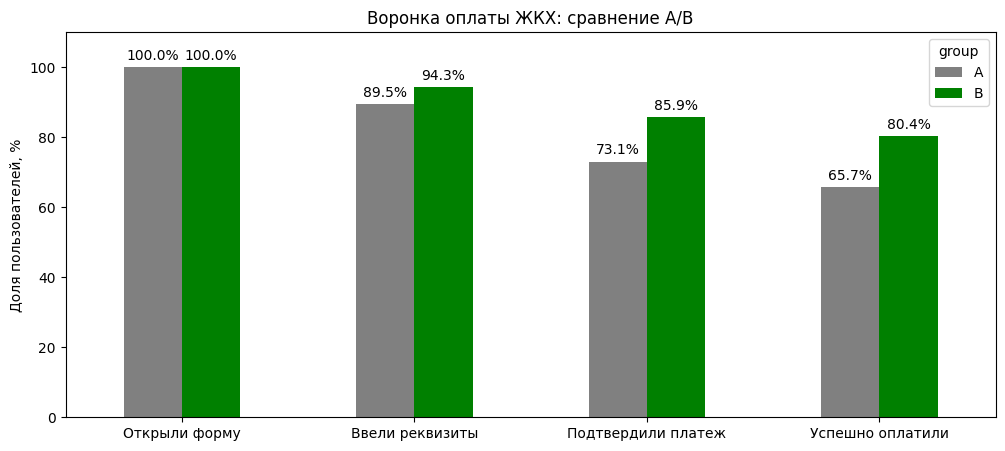

In [ ]:
payments1 = payments.copy()
payments1['opened'] = payments1['step1_opened'].notna().astype(int)
payments1['entered'] = payments1['step2_entered'].notna().astype(int)
payments1['confirmed'] = payments1['step3_confirmed'].notna().astype(int)
payments1['success'] = payments1['step4_success'].notna().astype(int)



payments2 = payments1[['user_id', 'opened', 'entered', 'confirmed', 'success']].groupby('user_id').max().reset_index()


funnel_users = payments2.merge(
    users[['user_id', 'group']],
    on = 'user_id',
    how = 'left'
)
funnel_counts = funnel_users.groupby('group')[['opened', 'entered', 'confirmed', 'success']].sum()
funnel_plt = funnel_counts.div(funnel_counts['opened'], axis = 0) * 100
ax = funnel_plt.T.plot(kind = 'bar', figsize = (12, 5), color = ['grey', 'green'], rot = 0, ylim = (0, 110), fontsize = 10)
ax.set_title('Воронка оплаты ЖКХ: сравнение A/B')
ax.set_ylabel('Доля пользователей, %')
ax.set_xticklabels(['Открыли форму', 'Ввели реквизиты', 'Подтвердили платеж', 'Успешно оплатили'])
for i in ax.containers:
  ax.bar_label(i, fmt = '%.1f%%', padding = 3)



In [ ]:
full_user_stats.groupby(['device_type', 'group'])['success'].agg(['count', 'sum', 'mean'])


count  sum      mean
device_type group                      
android     A        406  262  0.645320
            B        369  295  0.799458
ios         A        344  231  0.671512
            B        381  308  0.808399

In [ ]:
full_user_stats.groupby(['city', 'group'])['success'].agg(['count', 'sum', 'mean'])

count  sum      mean
city   group                      
Москва A        287  180  0.627178
       B        306  248  0.810458
Регион A        268  179  0.667910
       B        245  187  0.763265
СПб    A        194  133  0.685567
       B        199  168  0.844221

In [ ]:
age_users = full_user_stats.copy()
age_users = age_users[(age_users['age'] >= 18) & (age_users['age'] <= 100)]
age_users['age_group'] = pd.cut(age_users['age'], [19, 29, 39, 100], labels=['20-29', '30-39', '40-60'])
age_stats = age_users.groupby(['age_group', 'group'], observed=True)['success'].agg(['count', 'sum', 'mean'])
age_stats


count  sum      mean
age_group group                      
20-29     A        268  184  0.686567
          B        267  220  0.823970
30-39     A        334  215  0.643713
          B        325  254  0.781538
40-60     A        148   94  0.635135
          B        158  129  0.816456

In [ ]:
age_conv = age_stats['mean'].unstack()
age_conv['diff'] = (age_conv['B'] - age_conv['A']) * 100
age_conv


group,A,B,diff
age_group,,,
20-29,0.686567,0.823970,13.740287
30-39,0.643713,0.781538,13.782589
40-60,0.635135,0.816456,18.132056


In [ ]:
import scipy.stats
d = []
w = []
for i in age_conv.index:
    a = age_stats.loc[(i, 'A')]
    b = age_stats.loc[(i, 'B')]
    d.append(b['mean'] - a['mean'])
    w.append(1 / (a['mean'] * (1-a['mean']) / a['count'] + b['mean'] * (1-b['mean']) / b['count']))

m = sum(d[i] * w[i] for i in range(3)) / sum(w)
Q = sum(w[i] * (d[i] - m)**2 for i in range(3))
p_age = chi2.sf(Q, 2)
print(Q, p_age)


0.6057910979978527 0.7386762478146932


In [ ]:
pd.crosstab(
    users['city'],
    users['group'],
    normalize = 'columns'
)

group,A,B
city,,
Москва,0.383489,0.407457
Регион,0.356858,0.327563
СПб,0.259654,0.264980


In [ ]:
pd.crosstab(
    users['device_type'],
    users['group'],
    normalize = 'columns'
)

group,A,B
device_type,,
android,0.542553,0.491345
ios,0.457447,0.508655


In [ ]:
users_age = users[(10 <= users['age']) & (users['age'] <= 100)].copy()
users_age.groupby('group')['age'].agg(['count', 'mean', 'std', 'median'])

,count,mean,std,median
group,,,,
A,751,32.740346,7.815060,32.0
B,750,32.654667,7.775347,33.0


In [ ]:
device = pd.crosstab(
    users['device_type'],
    users['group']
)

chi_device_stat, p_value_device, a, b = scipy.stats.chi2_contingency(device)
print(chi_device_stat, p_value_device)

3.7434411106811734 0.05301515811225903


In [ ]:
city = pd.crosstab(
    users['city'],
    users['group']
)
chi_city_stat, p_value_city, a, b = scipy.stats.chi2_contingency(city)
print(chi_city_stat, p_value_city)

1.5276979237555195 0.4658698564445901


In [ ]:
age = pd.crosstab(
    age_users['age_group'],
    age_users['group']
)
chi_age_stat, p_value_age, a, b = scipy.stats.chi2_contingency(age)
print(chi_age_stat, p_value_age)


0.45158004981049704 0.7978856201863996


In [ ]:
full_user_stats.groupby(['city', 'group'])['success'].agg(['count', 'mean'])

count      mean
city   group                 
Москва A        287  0.627178
       B        306  0.810458
Регион A        268  0.667910
       B        245  0.763265
СПб    A        194  0.685567
       B        199  0.844221

In [ ]:
weights = full_user_stats['city'].value_counts(normalize = True)
meow = full_user_stats.groupby(['city', 'group'])['success'].agg('mean').unstack()
meow.mul(weights, axis = 0).sum()




,0
group,
A,0.656426
B,0.803159


In [ ]:
weights = full_user_stats['device_type'].value_counts(normalize = True)
meow = full_user_stats.groupby(['device_type', 'group'])['success'].agg('mean').unstack()
meow.mul(weights, axis = 0).sum()


,0
group,
A,0.657979
B,0.803779


In [ ]:
payments['time_entered'] = (
    payments['step2_entered'] - payments['step1_opened']
).dt.total_seconds()
payments['time_entered'].describe()

payments.groupby('group')['time_entered'].agg(['count', 'mean', 'std', 'median'])

,count,mean,std,median
group,,,,
A,1061,141.262959,107.816702,60.0
B,1194,145.728643,115.312237,60.0


In [ ]:
payments['time_confirmed'] = (
    payments['step3_confirmed'] - payments['step2_entered']
).dt.total_seconds()
payments.groupby('group')['time_confirmed'].agg(['count', 'mean', 'std', 'median'])

,count,mean,std,median
group,,,,
A,758,273.245383,110.623407,240.0
B,960,266.000000,119.148176,240.0


In [ ]:
payments['time_success'] = (
    payments['step4_success'] - payments['step3_confirmed']
).dt.total_seconds()
payments.groupby('group')['time_success'].agg(['count', 'mean', 'std', 'median'])

,count,mean,std,median
group,,,,
A,651,329.216590,65.246284,360.0
B,870,328.551724,61.634574,360.0


In [ ]:
first_payments = payments.sort_values('step1_opened').drop_duplicates('user_id').copy()

first_payments['time_entered'] = (
    first_payments['step2_entered'] - first_payments['step1_opened']
).dt.total_seconds()

first_payments['fast_entered'] = (
    first_payments['time_entered'] <= 180
).astype(int)

first_payments = first_payments.merge(
    users[['user_id', 'group']],
    on='user_id',
    how='left',
    suffixes=('_payment', '')
)

first_payments.groupby('group')['fast_entered'].agg(['count', 'sum', 'mean'])

,count,sum,mean
group,,,
A,750,465,0.620000
B,750,505,0.673333


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

fast_stats = first_payments.groupby('group')['fast_entered'].agg(['count', 'sum'])

z, p = proportions_ztest(
    [fast_stats.loc['B', 'sum'], fast_stats.loc['A', 'sum']],
    [fast_stats.loc['B', 'count'], fast_stats.loc['A', 'count']]
)

print(z, p)

2.1606370497172303 0.030723387102445474


Text(0, 0.5, 'Конверсия попыток, %')

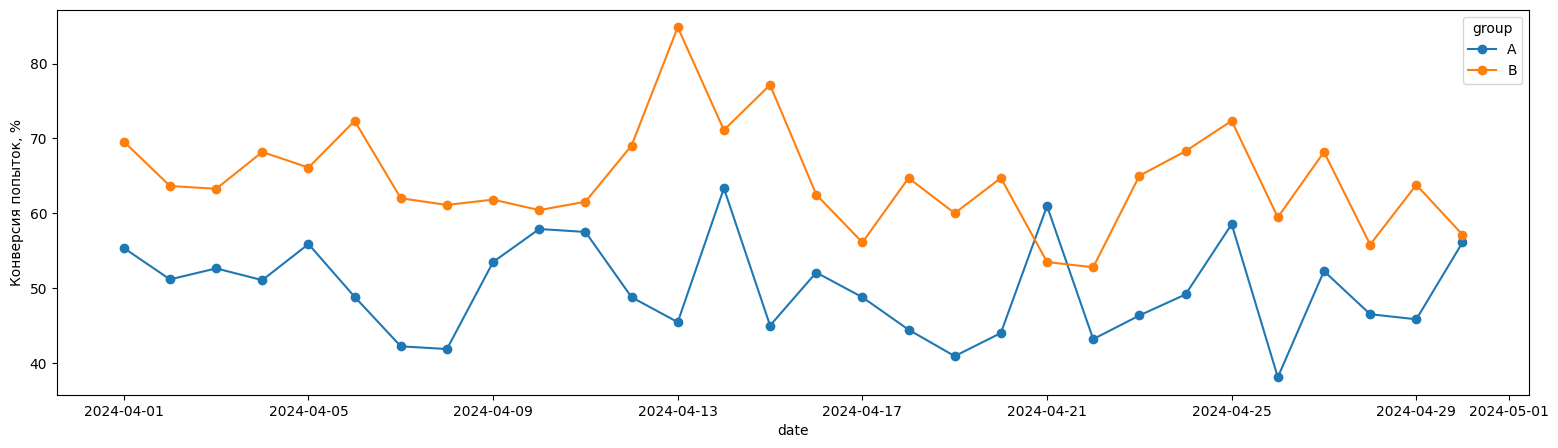

In [ ]:
payments['date'] = payments['step1_opened'].dt.date
daily_stats = payments.groupby(['date', 'group'])['success'].agg('mean').unstack()
ax = (daily_stats * 100).plot(marker = 'o', figsize = (19,5))
ax.set_ylabel('Конверсия попыток, %')




<Axes: xlabel='date'>

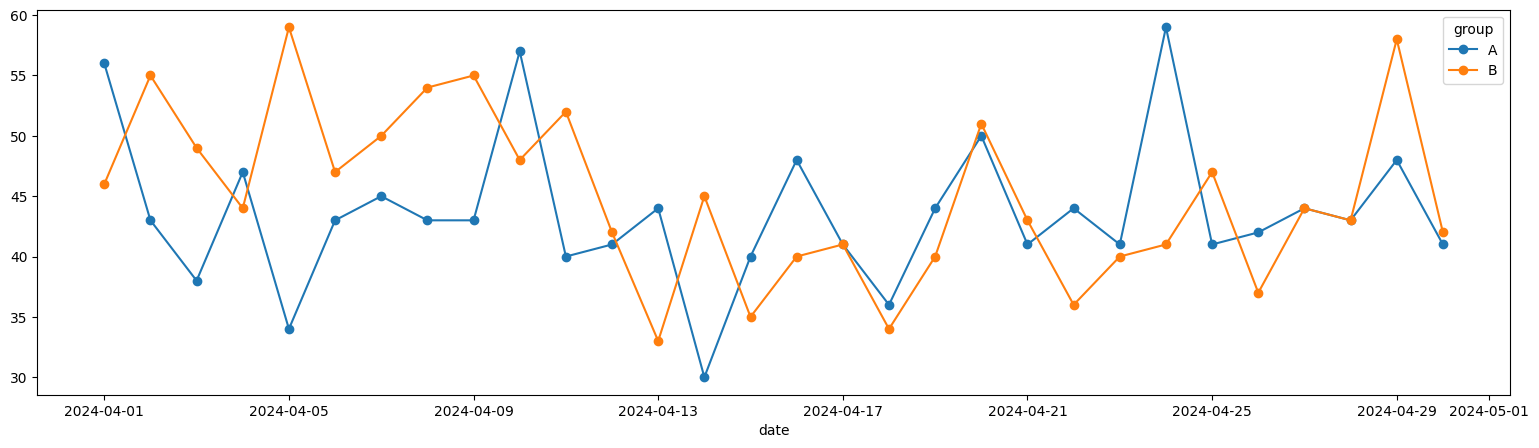

In [ ]:
daily_stats_count = payments.groupby(['date', 'group'])['success'].agg('count').unstack()
daily_stats_count.plot(marker = 'o', figsize = (19, 5))

(0.0, 100.0)

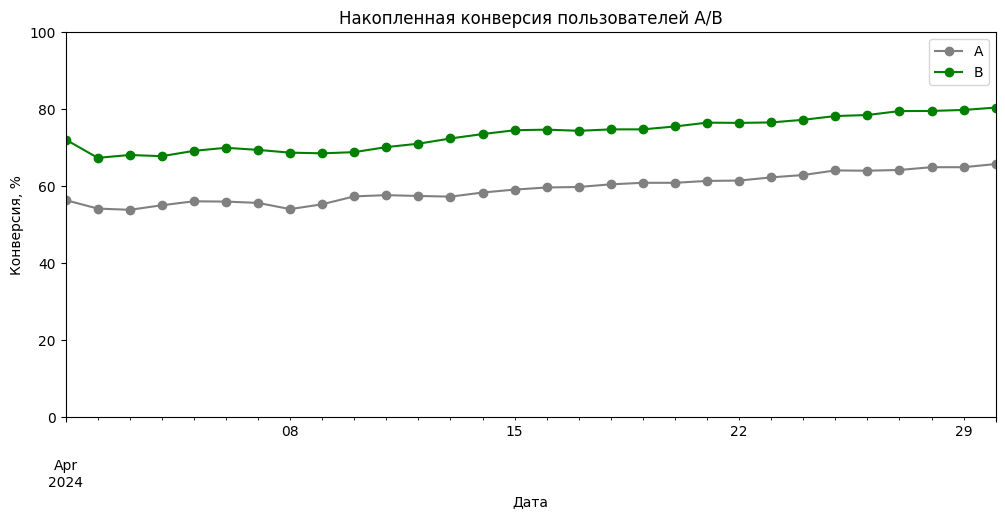

In [ ]:
first_dates = payments.groupby('user_id')[['step1_opened', 'step4_success']].min().reset_index()

first_dates = first_dates.merge(
    users[['user_id', 'group']],
    on='user_id',
    how='left'
)

first_dates['first_open'] = first_dates['step1_opened'].dt.normalize()
first_dates['first_success'] = first_dates['step4_success'].dt.normalize()

dates = pd.date_range('2024-04-01', '2024-04-30')
daily_users = pd.DataFrame(index=dates)

for group in ['A', 'B']:
    data = first_dates[first_dates['group'] == group]

    opened = data['first_open'].value_counts().reindex(dates, fill_value=0).cumsum()
    success = data['first_success'].value_counts().reindex(dates, fill_value=0).cumsum()

    daily_users[group] = success / opened * 100

ax = daily_users.plot(marker='o', figsize=(12, 5), color=['grey', 'green'])

ax.set_title('Накопленная конверсия пользователей A/B')
ax.set_ylabel('Конверсия, %')
ax.set_xlabel('Дата')
ax.set_ylim(0, 100)

In [ ]:
stats = full_user_stats.groupby('group')['success'].agg(['count', 'sum', 'mean'])

p_a = stats.loc['A', 'mean']
p_b = stats.loc['B', 'mean']
n_a = stats.loc['A', 'count']
n_b = stats.loc['B', 'count']

RR = p_b / p_a

SE_log = np.sqrt(
    (1 - p_a) / (n_a * p_a) +
    (1 - p_b) / (n_b * p_b)
)

CI_low_rel = (np.exp(np.log(RR) - 1.96 * SE_log) - 1) * 100
CI_high_rel = (np.exp(np.log(RR) + 1.96 * SE_log) - 1) * 100

print('Относительный прирост:', (RR - 1) * 100)
print('95% CI:', CI_low_rel, CI_high_rel)

Относительный прирост: 22.312373225152136
95% CI: 14.890279941051476 30.213945441205592


In [293]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

results = []

for col in ['device_type', 'city']:
    for segment in full_user_stats[col].dropna().unique():

        data = full_user_stats[full_user_stats[col] == segment]
        stats = data.groupby('group')['success'].agg(['count', 'sum', 'mean'])

        z, p = proportions_ztest(
            [stats.loc['B', 'sum'], stats.loc['A', 'sum']],
            [stats.loc['B', 'count'], stats.loc['A', 'count']]
        )

        diff = (stats.loc['B', 'mean'] - stats.loc['A', 'mean']) * 100

        results.append([segment, diff, z, p])

segment_results = pd.DataFrame(
    results,
    columns=['segment', 'diff_pp', 'z', 'p_value']
)

segment_results['p_holm'] = multipletests(
    segment_results['p_value'],
    method='holm'
)[1]

segment_results

,segment,diff_pp,z,p_value,p_holm
0,ios,13.688732,4.214277,2.505795e-05,0.000075
1,android,15.413780,4.766289,1.876502e-06,0.000008
2,Москва,18.327982,4.977139,6.453090e-07,0.000003
3,Регион,9.535486,2.385903,1.703726e-02,0.017037
4,СПб,15.865410,3.713623,2.043132e-04,0.000409
